# 12 MLP
โครงข่าย 27 → 64 → 32 → 1 (ReLU, output sigmoid) เทรนด้วย Adam, L2 และ dropout 20%
เขียน backpropagation เองและเช็คกับ numerical gradient หยุดก่อนเมื่อ validation loss ไม่ลด

โค้ด: `Model/Classification/MLP.py`  
ผลลัพธ์: `Results/Classification/12_MLP/`

## 1. เตรียมข้อมูล

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data, imbalance_weight
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from MLP import MLPClassifierScratch
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

out = Outputs("Classification", "12_MLP")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. เทรนโมเดล

In [2]:
model = MLPClassifierScratch(
    hidden_layers=(64, 32), l2=1e-2, dropout=0.2, learning_rate=1e-3, n_epochs=200, random_state=SEED
)
check_settings("MLP", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

sc = StandardScaler().fit(d.X_tr)
sk = MLPClassifier(
    (64, 32),
    alpha=1e-2,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    max_iter=300,
    random_state=SEED,
).fit(sc.transform(d.X_tr), d.y_tr, sample_weight=imbalance_weight(d.y_tr))
check = [
    sklearn_check(
        "MLP vs sklearn MLPClassifier (same shape)",
        np.nan,
        roc_auc(d.y_te, p_te),
        roc_auc(d.y_te, sk.predict_proba(sc.transform(d.X_te))[:, 1]),
        "AUC only",
    )
]
check.append(
    sklearn_check(
        "MLP back-propagation vs numerical gradient",
        MLPClassifierScratch(hidden_layers=(16, 8)).gradient_check(d.X_tr, d.y_tr, n_checks=30),
        np.nan,
        np.nan,
        "max relative error",
    )
)

settings match Common/model_zoo.py (13 values checked)


## 3. ผลลัพธ์

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2143        0.5000
log loss                            0.4611           NaN
accuracy                            0.3800        0.8199
precision                           0.1932        0.3462
recall / sensitivity                0.9115        0.1475
specificity                         0.2793           NaN
F1                                  0.3188        0.2069
ROC-AUC                             0.7089           NaN
PR-AUC                              0.2967           NaN
defaulters missed (FN)             27.0000           NaN

catches 91.1% of the 305 test defaulters (27 missed), flags 75.1% of applicants


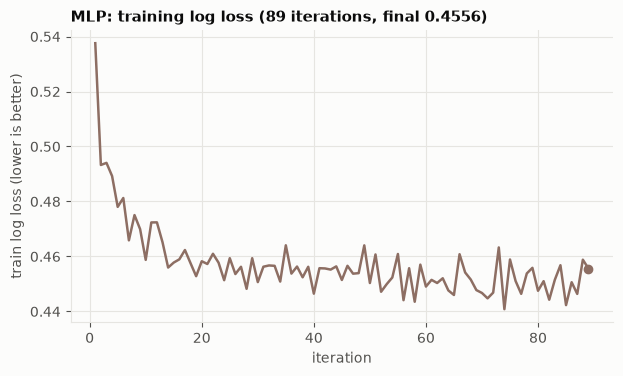

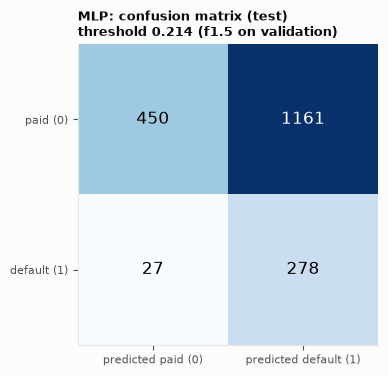

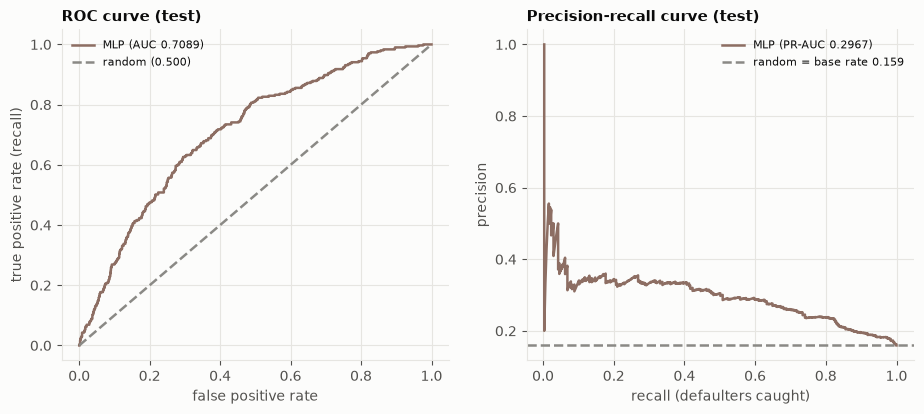

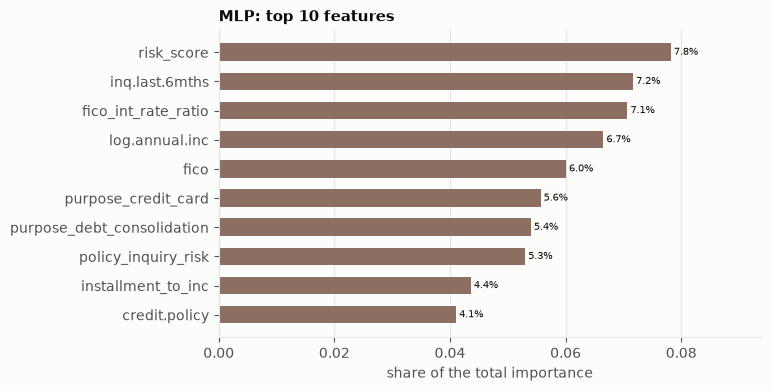


scratch vs library:
  MLP vs sklearn MLPClassifier (same shape)
    AUC scratch 0.7089 | AUC library 0.6954 | AUC only = nan
  MLP back-propagation vs numerical gradient
    AUC scratch nan | AUC library nan | max relative error = 3.81e-08

saved + reloaded Results/Classification/12_MLP/model.joblib (identical predictions: True)


In [3]:
row = report_classifier(out, "MLP", model, d, check)